<a href="https://colab.research.google.com/github/yashkumarcs24-bmsce/Bio-Inspired-Systems-Lab/blob/main/Grey_Wolf_Optimizer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np


class GreyWolfOptimizer:
    """Grey Wolf Optimizer (GWO) Implementation.

    Based on Mirjalili et al. (2014) and provided algorithmic steps.
    """

    def __init__(self, obj_func, lb, ub, dim, n_wolves=12, max_iter=100):
        """Initialize GWO parameters.

        Parameters:
        - obj_func: Objective function to minimize
        - lb: Lower bound array or float
        - ub: Upper bound array or float
        - dim: Number of decision variables (dimension)
        - n_wolves: Population size (number of grey wolves)
        - max_iter: Maximum number of iterations
        """
        self.obj_func = obj_func
        self.dim = dim
        self.n_wolves = n_wolves
        self.max_iter = max_iter

        # Format lower and upper bounds as numpy arrays
        self.lb = np.array(lb) if isinstance(lb, list) else np.full(dim, lb)
        self.ub = np.array(ub) if isinstance(ub, list) else np.full(dim, ub)

    def optimize(self):
        # ------------------------------------------------------------------
        # Step 1 & 3: Population Initialization
        # Initialize positions of n wolves randomly within bounds
        # ------------------------------------------------------------------
        positions = np.random.uniform(
            low=self.lb, high=self.ub, size=(self.n_wolves, self.dim)
        )

        # Initialize Alpha, Beta, Delta positions and their fitness scores
        alpha_pos = np.zeros(self.dim)
        alpha_score = float("inf")

        beta_pos = np.zeros(self.dim)
        beta_score = float("inf")

        delta_pos = np.zeros(self.dim)
        delta_score = float("inf")

        # ------------------------------------------------------------------
        # Step 5 & 7: Evaluate initial population & Assign Alpha, Beta, Delta
        # ------------------------------------------------------------------
        for i in range(self.n_wolves):
            fitness = self.obj_func(positions[i])

            # Update Alpha, Beta, Delta based on fitness (minimization)
            if fitness < alpha_score:
                delta_score, delta_pos = beta_score, beta_pos.copy()
                beta_score, beta_pos = alpha_score, alpha_pos.copy()
                alpha_score, alpha_pos = fitness, positions[i].copy()
            elif fitness < beta_score:
                delta_score, delta_pos = beta_score, beta_pos.copy()
                beta_score, beta_pos = fitness, positions[i].copy()
            elif fitness < delta_score:
                delta_score, delta_pos = fitness, positions[i].copy()

        # Track history of best score over iterations
        convergence_curve = [alpha_score]

        # ------------------------------------------------------------------
        # Step 8: Main Optimization Loop
        # ------------------------------------------------------------------
        for t in range(self.max_iter):
            # Linearly decrease parameter 'a' from 2 to 0
            a = 2.0 - t * (2.0 / self.max_iter)

            # Update position of each search agent
            for i in range(self.n_wolves):
                for j in range(self.dim):
                    # --- Position update relative to Alpha ---
                    r1, r2 = np.random.rand(), np.random.rand()
                    A1 = 2 * a * r1 - a  # Equation (3.3 / Eq 8)
                    C1 = 2 * r2  # Equation (3.4 / Eq 9)

                    D_alpha = abs(
                        C1 * alpha_pos[j] - positions[i, j]
                    )  # Equation (3.5)
                    X1 = alpha_pos[j] - A1 * D_alpha  # Equation (3.6)

                    # --- Position update relative to Beta ---
                    r1, r2 = np.random.rand(), np.random.rand()
                    A2 = 2 * a * r1 - a
                    C2 = 2 * r2

                    D_beta = abs(C2 * beta_pos[j] - positions[i, j])
                    X2 = beta_pos[j] - A2 * D_beta

                    # --- Position update relative to Delta ---
                    r1, r2 = np.random.rand(), np.random.rand()
                    A3 = 2 * a * r1 - a
                    C3 = 2 * r2

                    D_delta = abs(C3 * delta_pos[j] - positions[i, j])
                    X3 = delta_pos[j] - A3 * D_delta

                    # Average of Alpha, Beta, Delta positions (Equation 3.7 / Eq 12)
                    positions[i, j] = (X1 + X2 + X3) / 3.0

                # Clip positions within lower and upper search bounds
                positions[i] = np.clip(positions[i], self.lb, self.ub)

                # ----------------------------------------------------------
                # Step 13: Evaluate fitness of updated wolf
                # ----------------------------------------------------------
                fitness = self.obj_func(positions[i])

                # ----------------------------------------------------------
                # Step 15: Update Alpha, Beta, Delta wolves
                # ----------------------------------------------------------
                if fitness < alpha_score:
                    delta_score, delta_pos = beta_score, beta_pos.copy()
                    beta_score, beta_pos = alpha_score, alpha_pos.copy()
                    alpha_score, alpha_pos = fitness, positions[i].copy()
                elif fitness < beta_score:
                    delta_score, delta_pos = beta_score, beta_pos.copy()
                    beta_score, beta_pos = fitness, positions[i].copy()
                elif fitness < delta_score:
                    delta_score, delta_pos = fitness, positions[i].copy()

            convergence_curve.append(alpha_score)

        # ------------------------------------------------------------------
        # Step 18: Produce and return the best solution found (Alpha)
        # ------------------------------------------------------------------
        return alpha_pos, alpha_score, convergence_curve


# =====================================================================
# Example Run: Minimizing the Korn function from slide 21
# f(x1, x2) = (x1 - 5)^2 + (x2 - 2)^2   ---> Global Minimum at (5, 2)
# =====================================================================
if __name__ == "__main__":

    def korn_function(x):
        return (x[0] - 5.0) ** 2 + (x[1] - 2.0) ** 2

    # Problem configuration
    dimensions = 2
    lower_bounds = [-10.0, -10.0]
    upper_bounds = [10.0, 10.0]
    num_wolves = 12
    iterations = 50

    # Instantiate and execute optimizer
    gwo = GreyWolfOptimizer(
        obj_func=korn_function,
        lb=lower_bounds,
        ub=upper_bounds,
        dim=dimensions,
        n_wolves=num_wolves,
        max_iter=iterations,
    )

    best_solution, best_fitness, curve = gwo.optimize()

    # Display results
    print("Optimization Complete!")
    print("-" * 40)
    print(f"Best Position Found (X_alpha) : {best_solution}")
    print(f"Best Fitness Value            : {best_fitness:.8f}")
    print(f"Theoretical Optimum           : [5.0, 2.0] with fitness 0.0")

Optimization Complete!
----------------------------------------
Best Position Found (X_alpha) : [4.99572781 1.99262866]
Best Fitness Value            : 0.00007259
Theoretical Optimum           : [5.0, 2.0] with fitness 0.0


In [ ]:
pip install pandas matplotlib seaborn

=== TABLE 5: Unimodal Benchmark Functions (Average Results) ===
Function      GWO      PSO      GSA       DE      FEP
      F1 6.59E-28 0.000136 2.53E-16 8.20E-14 0.000570
      F2 7.18E-17 0.042144 0.055655 1.50E-09 0.008100
      F3 3.29E-06 70.12562 896.5347 6.80E-11 0.016000
      F4 5.61E-07 1.086481 7.354870 0.000000 0.300000
      F5 26.81258 96.71832 67.54309 0.000000 5.060000
      F6 0.816579 0.000102 2.50E-16 0.000000 0.000000
      F7 0.002213 0.122854 0.089441 0.004630 0.141500

=== TABLE 6: Multimodal Benchmark Functions (Average Results) ===
Function      GWO      PSO      GSA       DE      FEP
      F8 -6123.10 -4841.29 -2821.07 -11080.1 -12554.5
      F9 0.310521 46.70423 25.96841 69.20000 0.046000
     F10 1.06E-13 0.276015 0.062087 9.70E-08 0.018000
     F11 0.004485 0.009215 27.70154 0.000000 0.016000
     F12 0.053438 0.006917 1.799617 7.90E-15 9.20E-06
     F13 0.654464 0.006675 8.899084 5.10E-14 0.000160

=== TABLE 7: Fixed-Dimension Multimodal Benchmark Function

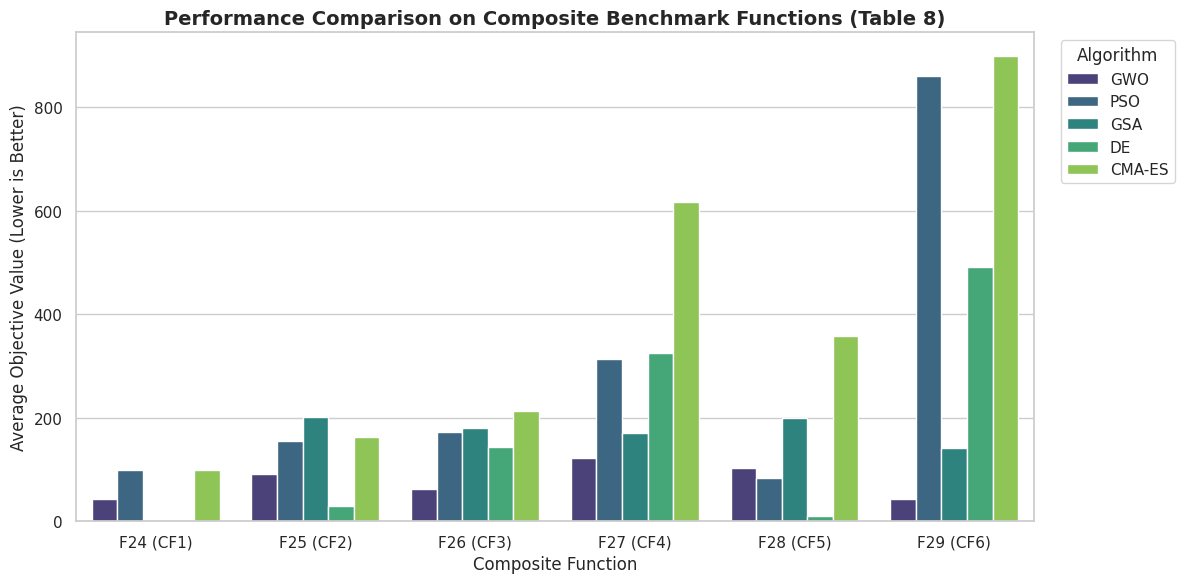

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")

# =====================================================================
# DATA DEFINITIONS (Extracted from Tables 5, 6, 7, and 8 of the paper)
# =====================================================================

# Table 5: Unimodal Benchmark Functions (Exploitation Analysis)
data_unimodal = {
    "Function": ["F1", "F2", "F3", "F4", "F5", "F6", "F7"],
    "GWO": ["6.59E-28", "7.18E-17", "3.29E-06", "5.61E-07", "26.81258", "0.816579", "0.002213"],
    "PSO": ["0.000136", "0.042144", "70.12562", "1.086481", "96.71832", "0.000102", "0.122854"],
    "GSA": ["2.53E-16", "0.055655", "896.5347", "7.354870", "67.54309", "2.50E-16", "0.089441"],
    "DE": ["8.20E-14", "1.50E-09", "6.80E-11", "0.000000", "0.000000", "0.000000", "0.004630"],
    "FEP": ["0.000570", "0.008100", "0.016000", "0.300000", "5.060000", "0.000000", "0.141500"],
}

# Table 6: Multimodal Benchmark Functions (Exploration Analysis)
data_multimodal = {
    "Function": ["F8", "F9", "F10", "F11", "F12", "F13"],
    "GWO": ["-6123.10", "0.310521", "1.06E-13", "0.004485", "0.053438", "0.654464"],
    "PSO": ["-4841.29", "46.70423", "0.276015", "0.009215", "0.006917", "0.006675"],
    "GSA": ["-2821.07", "25.96841", "0.062087", "27.70154", "1.799617", "8.899084"],
    "DE": ["-11080.1", "69.20000", "9.70E-08", "0.000000", "7.90E-15", "5.10E-14"],
    "FEP": ["-12554.5", "0.046000", "0.018000", "0.016000", "9.20E-06", "0.000160"],
}

# Table 7: Fixed-Dimension Multimodal Benchmark Functions
data_fixed_multimodal = {
    "Function": ["F14", "F15", "F16", "F17", "F18", "F19", "F20", "F21", "F22", "F23"],
    "GWO": ["4.042493", "0.000337", "-1.03163", "0.397889", "3.000028", "-3.86263", "-3.28654", "-10.1514", "-10.4015", "-10.5343"],
    "PSO": ["3.627168", "0.000577", "-1.03163", "0.397887", "3.000000", "-3.86278", "-3.26634", "-6.86510", "-8.45653", "-9.95291"],
    "GSA": ["5.859838", "0.003673", "-1.03163", "0.397887", "3.000000", "-3.86278", "-3.31778", "-5.95512", "-9.68447", "-10.5364"],
    "DE": ["0.998004", "4.50E-14", "-1.03163", "0.397887", "3.000000", "N/A", "N/A", "-10.1532", "-10.4029", "-10.5364"],
    "FEP": ["1.220000", "0.000500", "-1.03000", "0.398000", "3.020000", "-3.86000", "-3.27000", "-5.52000", "-5.53000", "-6.57000"],
}

# Table 8: Composite Benchmark Functions (Local Optima Avoidance & Balance)
data_composite = {
    "Function": ["F24 (CF1)", "F25 (CF2)", "F26 (CF3)", "F27 (CF4)", "F28 (CF5)", "F29 (CF6)"],
    "GWO": [43.83544, 91.80086, 61.43776, 123.1235, 102.1429, 43.14261],
    "PSO": [100.0000, 155.9100, 172.0300, 314.3000, 83.45000, 861.4200],
    "GSA": [6.63e-17, 200.6202, 180.0000, 170.0000, 200.0000, 142.0906],
    "DE": [0.067500, 28.75900, 144.4100, 324.8600, 10.78900, 490.9400],
    "CMA-ES": [100.0000, 161.9900, 214.0600, 616.4000, 358.3000, 900.2600],
}

# Convert to pandas DataFrames
df_unimodal = pd.DataFrame(data_unimodal)
df_multimodal = pd.DataFrame(data_multimodal)
df_fixed = pd.DataFrame(data_fixed_multimodal)
df_composite = pd.DataFrame(data_composite)

# Print tables to console
print("=== TABLE 5: Unimodal Benchmark Functions (Average Results) ===")
print(df_unimodal.to_string(index=False))
print("\n=== TABLE 6: Multimodal Benchmark Functions (Average Results) ===")
print(df_multimodal.to_string(index=False))
print("\n=== TABLE 7: Fixed-Dimension Multimodal Benchmark Functions (Average Results) ===")
print(df_fixed.to_string(index=False))
print("\n=== TABLE 8: Composite Benchmark Functions (Average Results) ===")
print(df_composite.to_string(index=False))

# =====================================================================
# GRAPH VISUALIZATION: Composite Functions Performance Comparison
# =====================================================================

# Melt the composite data frame for seaborn plotting
df_composite_melted = df_composite.melt(
    id_vars=["Function"],
    var_name="Algorithm",
    value_name="Average Score"
)

fig, ax = plt.subplots(figsize=(12, 6))

# Grouped bar chart comparison
sns.barplot(
    data=df_composite_melted,
    x="Function",
    y="Average Score",
    hue="Algorithm",
    palette="viridis",
    ax=ax
)

ax.set_title("Performance Comparison on Composite Benchmark Functions (Table 8)", fontsize=14, fontweight="bold")
ax.set_xlabel("Composite Function", fontsize=12)
ax.set_ylabel("Average Objective Value (Lower is Better)", fontsize=12)
ax.legend(title="Algorithm", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

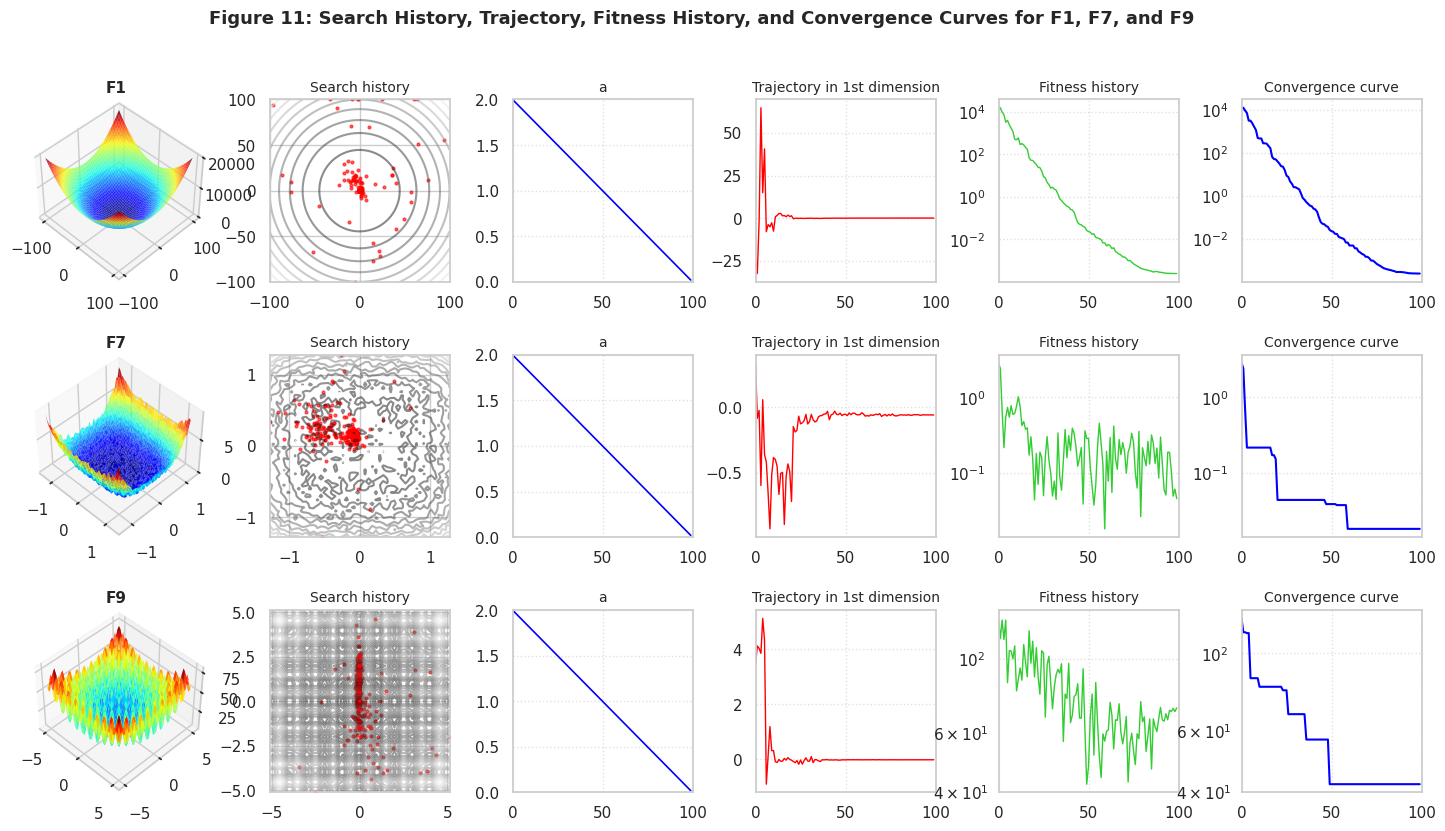

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Set random seed for reproducibility
np.random.seed(42)

# =====================================================================
# BENCHMARK FUNCTIONS (F1, F7, F9 from paper)
# =====================================================================


def f1_sphere(x):
    """F1: Sphere Function (Unimodal)"""
    return np.sum(x**2)


def f7_quartic(x):
    """F7: Quartic with Noise (Unimodal)"""
    return np.sum(
        np.arange(1, len(x) + 1) * (x**4)
    ) + np.random.uniform(0, 1)


def f9_rastrigin(x):
    """F9: Rastrigin Function (Multimodal)"""
    return np.sum(x**2 - 10 * np.cos(2 * np.pi * x) + 10)


# Function configurations: (name, function, dimension, lower_bound, upper_bound)
functions_info = [
    ("F1", f1_sphere, 10, -100, 100),
    ("F7", f7_quartic, 10, -1.28, 1.28),
    ("F9", f9_rastrigin, 10, -5.12, 5.12),
]

# =====================================================================
# GREY WOLF OPTIMIZER WITH ANALYTICAL TRACKING
# =====================================================================


class GWO_Tracker:

    def __init__(self, obj_func, dim, lb, ub, n_wolves=6, max_iter=100):
        self.obj_func = obj_func
        self.dim = dim
        self.lb = lb
        self.ub = ub
        self.n_wolves = n_wolves
        self.max_iter = max_iter

    def optimize(self):
        # Initialize positions
        positions = np.random.uniform(
            self.lb, self.ub, (self.n_wolves, self.dim)
        )

        alpha_pos, alpha_score = np.zeros(self.dim), float("inf")
        beta_pos, beta_score = np.zeros(self.dim), float("inf")
        delta_pos, delta_score = np.zeros(self.dim), float("inf")

        # Tracking metrics for Figure 11 plots
        all_positions = []  # Search History
        trajectory = []  # 1st particle trajectory in 1st dim
        a_history = []  # Parameter 'a' decay
        fitness_history = []  # Best fitness of agents per iteration
        convergence_curve = []  # Best global fitness overall

        # Initial fitness evaluation
        for i in range(self.n_wolves):
            fitness = self.obj_func(positions[i])
            if fitness < alpha_score:
                delta_score, delta_pos = beta_score, beta_pos.copy()
                beta_score, beta_pos = alpha_score, alpha_pos.copy()
                alpha_score, alpha_pos = fitness, positions[i].copy()
            elif fitness < beta_score:
                delta_score, delta_pos = beta_score, beta_pos.copy()
                beta_score, beta_pos = fitness, positions[i].copy()
            elif fitness < delta_score:
                delta_score, delta_pos = fitness, positions[i].copy()

        # Optimization Loop
        for t in range(self.max_iter):
            a = 2.0 - t * (2.0 / self.max_iter)  # Parameter 'a' decreases 2 -> 0
            a_history.append(a)
            all_positions.append(positions.copy()[:, :2])  # Save 2D positions
            trajectory.append(positions[0, 0])  # Particle 0, Dimension 0

            iter_best_fitness = float("inf")

            for i in range(self.n_wolves):
                for j in range(self.dim):
                    # Alpha update
                    r1, r2 = np.random.rand(), np.random.rand()
                    A1, C1 = 2 * a * r1 - a, 2 * r2
                    D_alpha = abs(C1 * alpha_pos[j] - positions[i, j])
                    X1 = alpha_pos[j] - A1 * D_alpha

                    # Beta update
                    r1, r2 = np.random.rand(), np.random.rand()
                    A2, C2 = 2 * a * r1 - a, 2 * r2
                    D_beta = abs(C2 * beta_pos[j] - positions[i, j])
                    X2 = beta_pos[j] - A2 * D_beta

                    # Delta update
                    r1, r2 = np.random.rand(), np.random.rand()
                    A3, C3 = 2 * a * r1 - a, 2 * r2
                    D_delta = abs(C3 * delta_pos[j] - positions[i, j])
                    X3 = delta_pos[j] - A3 * D_delta

                    positions[i, j] = (X1 + X2 + X3) / 3.0

                # Bound handling
                positions[i] = np.clip(positions[i], self.lb, self.ub)

                # Fitness Evaluation
                fitness = self.obj_func(positions[i])
                if fitness < iter_best_fitness:
                    iter_best_fitness = fitness

                # Hierarchy Update
                if fitness < alpha_score:
                    delta_score, delta_pos = beta_score, beta_pos.copy()
                    beta_score, beta_pos = alpha_score, alpha_pos.copy()
                    alpha_score, alpha_pos = fitness, positions[i].copy()
                elif fitness < beta_score:
                    delta_score, delta_pos = beta_score, beta_pos.copy()
                    beta_score, beta_pos = fitness, positions[i].copy()
                elif fitness < delta_score:
                    delta_score, delta_pos = fitness, positions[i].copy()

            fitness_history.append(iter_best_fitness)
            convergence_curve.append(alpha_score)

        return {
            "all_positions": np.array(all_positions),
            "trajectory": np.array(trajectory),
            "a_history": np.array(a_history),
            "fitness_history": np.array(fitness_history),
            "convergence_curve": np.array(convergence_curve),
        }


# =====================================================================
# FIGURE 11 MULTI-PANEL PLOTTING CODE
# =====================================================================

fig = plt.figure(figsize=(18, 9))
plt.subplots_adjust(wspace=0.35, hspace=0.4)

row_idx = 0

for func_name, func, dim, lb, ub in functions_info:
    # Run GWO tracker
    gwo = GWO_Tracker(
        obj_func=func, dim=dim, lb=lb, ub=ub, n_wolves=6, max_iter=100
    )
    res = gwo.optimize()

    # Grid mesh for 3D Surface & Contour
    x_range = np.linspace(lb, ub, 50)
    y_range = np.linspace(lb, ub, 50)
    X, Y = np.meshgrid(x_range, y_range)

    Z = np.zeros_like(X)
    for i in range(50):
        for j in range(50):
            # Evaluate 2D slices for visualization
            Z[i, j] = func(
                np.array(
                    [X[i, j], Y[i, j]] + [0] * (dim - 2)
                )  # Fill remaining dims with 0
            )

    # -----------------------------------------------------------------
    # Column 1: 3D Surface Topology Plot
    # -----------------------------------------------------------------
    ax1 = fig.add_subplot(3, 6, row_idx * 6 + 1, projection="3d")
    ax1.plot_surface(X, Y, Z, cmap="jet", edgecolor="none", alpha=0.85)
    ax1.set_title(func_name, fontweight="bold", fontsize=11)
    ax1.view_init(elev=45, azim=-45)

    # -----------------------------------------------------------------
    # Column 2: 2D Search History Plot
    # -----------------------------------------------------------------
    ax2 = fig.add_subplot(3, 6, row_idx * 6 + 2)
    ax2.contour(X, Y, Z, levels=12, cmap="gray", alpha=0.5)

    # Plot all positions of search agents
    flattened_positions = res["all_positions"].reshape(-1, 2)
    ax2.scatter(
        flattened_positions[:, 0],
        flattened_positions[:, 1],
        c="red",
        s=4,
        alpha=0.6,
        marker="o",
    )
    ax2.set_xlim([lb, ub])
    ax2.set_ylim([lb, ub])
    ax2.set_title("Search history", fontsize=10)

    # -----------------------------------------------------------------
    # Column 3: Parameter 'a' Decay Plot
    # -----------------------------------------------------------------
    ax3 = fig.add_subplot(3, 6, row_idx * 6 + 3)
    ax3.plot(res["a_history"], color="blue", linewidth=1.2)
    ax3.set_xlim([0, 100])
    ax3.set_ylim([0, 2])
    ax3.set_title("a", fontsize=10)
    ax3.grid(True, linestyle=":", alpha=0.6)

    # -----------------------------------------------------------------
    # Column 4: Trajectory in 1st Dimension
    # -----------------------------------------------------------------
    ax4 = fig.add_subplot(3, 6, row_idx * 6 + 4)
    ax4.plot(res["trajectory"], color="red", linewidth=1)
    ax4.set_xlim([0, 100])
    ax4.set_title("Trajectory in 1st dimension", fontsize=10)
    ax4.grid(True, linestyle=":", alpha=0.6)

    # -----------------------------------------------------------------
    # Column 5: Fitness History (Semilog Plot)
    # -----------------------------------------------------------------
    ax5 = fig.add_subplot(3, 6, row_idx * 6 + 5)
    ax5.semilogy(res["fitness_history"], color="limegreen", linewidth=1)
    ax5.set_xlim([0, 100])
    ax5.set_title("Fitness history", fontsize=10)
    ax5.grid(True, linestyle=":", alpha=0.6)

    # -----------------------------------------------------------------
    # Column 6: Convergence Curve (Semilog Plot)
    # -----------------------------------------------------------------
    ax6 = fig.add_subplot(3, 6, row_idx * 6 + 6)
    ax6.semilogy(res["convergence_curve"], color="blue", linewidth=1.5)
    ax6.set_xlim([0, 100])
    ax6.set_title("Convergence curve", fontsize=10)
    ax6.grid(True, linestyle=":", alpha=0.6)

    row_idx += 1

plt.suptitle(
    "Figure 11: Search History, Trajectory, Fitness History, and Convergence Curves for F1, F7, and F9",
    fontsize=13,
    fontweight="bold",
    y=0.98,
)
plt.show()